In [3]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Conv2D,MaxPooling2D,Flatten 
import matplotlib.pyplot as plt
import numpy as np
import os

In [4]:

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current working directory:
C:\Users\sneha\OneDrive\Documents\DNN\CNN

Files and folders here:
['.ipynb_checkpoints', 'archive', 'CatVsDog-CNN.ipynb', 'CNN_PADDING.ipynb', 'CNN_STRIDES.ipynb', 'LeNet-5.ipynb']


In [5]:
import os

dataset_path = os.path.join(os.getcwd(), "archive")

print("Dataset path:", dataset_path)
print("\nContents of archive:")

for item in os.listdir(dataset_path):
    print(item)

Dataset path: C:\Users\sneha\OneDrive\Documents\DNN\CNN\archive

Contents of archive:
test
train


In [6]:
train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")

print("Training folder contents:")
print(os.listdir(train_path))

print("\nTesting folder contents:")
print(os.listdir(test_path))

Training folder contents:
['cats', 'dogs']

Testing folder contents:
['cats', 'dogs']


In [7]:
print("Training images")
print("Cats:", len(os.listdir(os.path.join(train_path, "cats"))))
print("Dogs:", len(os.listdir(os.path.join(train_path, "dogs"))))

print("\nTesting images")
print("Cats:", len(os.listdir(os.path.join(test_path, "cats"))))
print("Dogs:", len(os.listdir(os.path.join(test_path, "dogs"))))

Training images
Cats: 10000
Dogs: 10000

Testing images
Cats: 2500
Dogs: 2500


In [8]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [9]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("First 5 labels:")
    print(labels[:5].numpy().flatten())

Images shape: (32, 128, 128, 3)
Labels shape: (32, 1)
First 5 labels:
[1. 1. 0. 1. 0.]


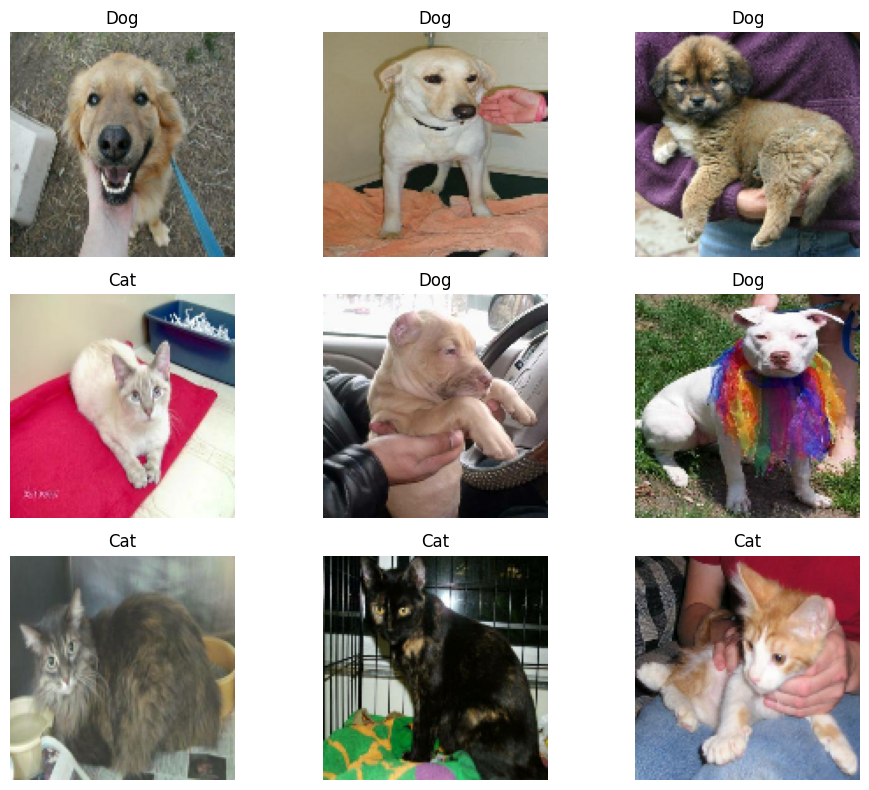

In [10]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy()[0])
        plt.title("Dog" if label == 1 else "Cat")

        plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

test_ds = test_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

In [22]:
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),

     layers.Dense(128, activation="relu"),

    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_25 (Conv2D)                   │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_24 (MaxPooling2D)      │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_26 (Conv2D)                   │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_25 (MaxPooling2D)      │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_27 (Conv2D)                   │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_26 (MaxPooling2D)      │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_5 (Flatten)                  │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
train_ds = train_ds.shuffle(
    buffer_size=1000,
    seed=42,
    reshuffle_each_iteration=True
)

total_batches = tf.data.experimental.cardinality(train_ds).numpy()
val_batches = int(total_batches * 0.2)

val_ds = train_ds.take(val_batches)
train_ds = train_ds.skip(val_batches)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Training batches: 500
Validation batches: 125


In [24]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [25]:
history_adam = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5


C:\Users\sneha\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


500/500 ━━━━━━━━━━━━━━━━━━━━ 201s 284ms/step - accuracy: 0.6391 - auc: 0.6960 - loss: 0.6304 - precision: 0.6414 - recall: 0.6280 - val_accuracy: 0.7172 - val_auc: 0.7924 - val_loss: 0.5487 - val_precision: 0.7437 - val_recall: 0.6783
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 183s 346ms/step - accuracy: 0.7385 - auc: 0.8167 - loss: 0.5254 - precision: 0.7462 - recall: 0.7233 - val_accuracy: 0.7722 - val_auc: 0.8835 - val_loss: 0.4624 - val_precision: 0.8693 - val_recall: 0.6321
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 202s 377ms/step - accuracy: 0.7836 - auc: 0.8665 - loss: 0.4578 - precision: 0.7910 - recall: 0.7754 - val_accuracy: 0.7903 - val_auc: 0.8731 - val_loss: 0.4488 - val_precision: 0.7801 - val_recall: 0.8048
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 188s 351ms/step - accuracy: 0.8184 - auc: 0.8990 - loss: 0.4032 - precision: 0.8210 - recall: 0.8134 - val_accuracy: 0.8547 - val_auc: 0.9440 - val_loss: 0.3328 - val_precision: 0.8075 - val_recall: 0.9345
Epoch 5/5
500/500 ━━━━━━━━━━━━

In [27]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [28]:
val_results = model.evaluate(val_ds, return_dict=True)

print("\nAdam Optimizer — Validation Results")
for metric, value in val_results.items():
    print(f"{metric}: {value:.4f}")

125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 53ms/step - accuracy: 0.8840 - auc: 0.9525 - loss: 0.3061 - precision: 0.9173 - recall: 0.8465

Adam Optimizer — Validation Results
accuracy: 0.8840
auc: 0.9525
loss: 0.3061
precision: 0.9173
recall: 0.8465


In [29]:
def create_cnn():
    model = models.Sequential([
        layers.Input(shape=(128, 128, 3)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid")
    ])

    return model


model_sgd = create_cnn()

print("Fresh CNN created for SGD.")

Fresh CNN created for SGD.


In [30]:
model_sgd.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [31]:
history_sgd = model_sgd.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 152s 282ms/step - accuracy: 0.5437 - auc: 0.5660 - loss: 0.6866 - precision: 0.5396 - recall: 0.6015 - val_accuracy: 0.5847 - val_auc: 0.6410 - val_loss: 0.6770 - val_precision: 0.5649 - val_recall: 0.7434
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 139s 257ms/step - accuracy: 0.5831 - auc: 0.6219 - loss: 0.6713 - precision: 0.5770 - recall: 0.6039 - val_accuracy: 0.6190 - val_auc: 0.6813 - val_loss: 0.6546 - val_precision: 0.6003 - val_recall: 0.7797
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 129s 241ms/step - accuracy: 0.6070 - auc: 0.6503 - loss: 0.6581 - precision: 0.6050 - recall: 0.6216 - val_accuracy: 0.6438 - val_auc: 0.6987 - val_loss: 0.6385 - val_precision: 0.6684 - val_recall: 0.5726
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 126s 236ms/step - accuracy: 0.6229 - auc: 0.6765 - loss: 0.6436 - precision: 0.6229 - recall: 0.6222 - val_accuracy: 0.6560 - val_auc: 0.7311 - val_loss: 0.6227 - val_precision: 0.6267 - val_recall: 0.7598
Epoch 5/5
500/500 ━━

In [32]:
sgd_results = model_sgd.evaluate(
    val_ds,
    return_dict=True
)

print("\nSGD Optimizer — Validation Results")

for metric, value in sgd_results.items():
    print(f"{metric}: {value:.4f}")

125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 51ms/step - accuracy: 0.6612 - auc: 0.7353 - loss: 0.6116 - precision: 0.7191 - recall: 0.5375

SGD Optimizer — Validation Results
accuracy: 0.6612
auc: 0.7353
loss: 0.6116
precision: 0.7191
recall: 0.5375


In [33]:
model_rmsprop = create_cnn()

print("Fresh CNN created for RMSprop.")

Fresh CNN created for RMSprop.


In [34]:
model_rmsprop.compile(
    optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [35]:
history_rmsprop = model_rmsprop.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 136s 249ms/step - accuracy: 0.6204 - auc: 0.6777 - loss: 0.6449 - precision: 0.6253 - recall: 0.6066 - val_accuracy: 0.7150 - val_auc: 0.8001 - val_loss: 0.5399 - val_precision: 0.7365 - val_recall: 0.6920
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 158s 296ms/step - accuracy: 0.7406 - auc: 0.8155 - loss: 0.5280 - precision: 0.7432 - recall: 0.7334 - val_accuracy: 0.7567 - val_auc: 0.8745 - val_loss: 0.4940 - val_precision: 0.8837 - val_recall: 0.5825
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 147s 276ms/step - accuracy: 0.7820 - auc: 0.8617 - loss: 0.4666 - precision: 0.7831 - recall: 0.7764 - val_accuracy: 0.8152 - val_auc: 0.9048 - val_loss: 0.3987 - val_precision: 0.8511 - val_recall: 0.7562
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 145s 271ms/step - accuracy: 0.8141 - auc: 0.8937 - loss: 0.4145 - precision: 0.8127 - recall: 0.8181 - val_accuracy: 0.8445 - val_auc: 0.9403 - val_loss: 0.3441 - val_precision: 0.9038 - val_recall: 0.7695
Epoch 5/5
500/500 ━━

In [36]:
rmsprop_results = model_rmsprop.evaluate(
    val_ds,
    return_dict=True
)

print("\nRMSprop Optimizer — Validation Results")

for metric, value in rmsprop_results.items():
    print(f"{metric}: {value:.4f}")

125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - accuracy: 0.8643 - auc: 0.9501 - loss: 0.3211 - precision: 0.9280 - recall: 0.7923

RMSprop Optimizer — Validation Results
accuracy: 0.8643
auc: 0.9501
loss: 0.3211
precision: 0.9280
recall: 0.7923


In [37]:
import pandas as pd

comparison = pd.DataFrame({
    "Adam": val_results,
    "SGD": sgd_results,
    "RMSprop": rmsprop_results
})

print(comparison.round(4))

             Adam     SGD  RMSprop
accuracy   0.8840  0.6612   0.8643
auc        0.9525  0.7353   0.9501
loss       0.3061  0.6116   0.3211
precision  0.9173  0.7191   0.9280
recall     0.8465  0.5375   0.7923


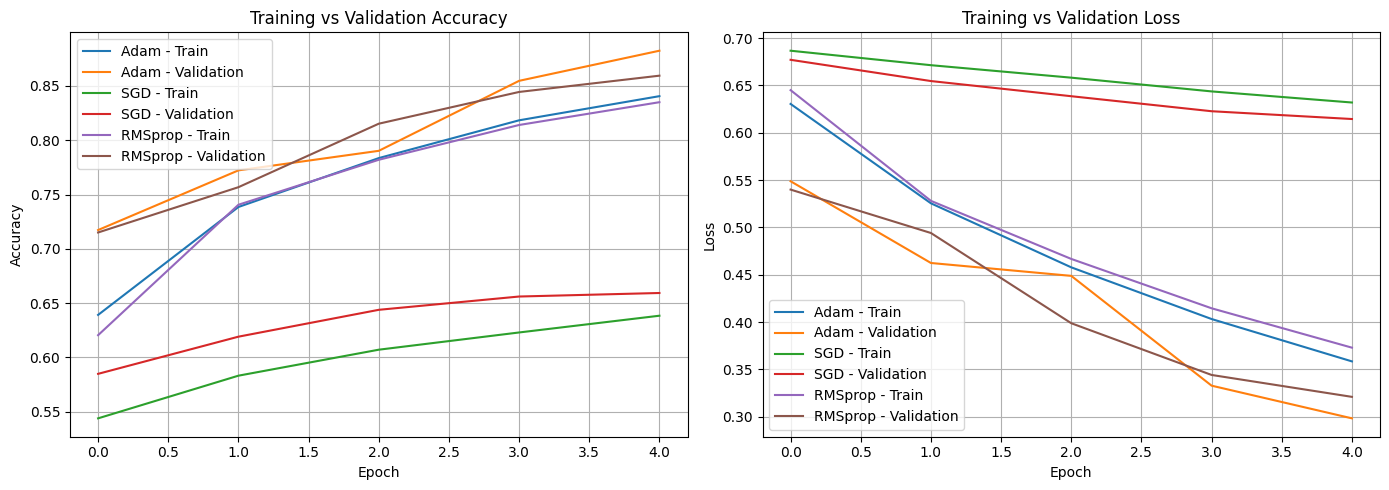

In [38]:
plt.figure(figsize=(14, 5))

# Accuracy comparison
plt.subplot(1, 2, 1)

plt.plot(history_adam.history["accuracy"], label="Adam - Train")
plt.plot(history_adam.history["val_accuracy"], label="Adam - Validation")

plt.plot(history_sgd.history["accuracy"], label="SGD - Train")
plt.plot(history_sgd.history["val_accuracy"], label="SGD - Validation")

plt.plot(history_rmsprop.history["accuracy"], label="RMSprop - Train")
plt.plot(history_rmsprop.history["val_accuracy"], label="RMSprop - Validation")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss comparison
plt.subplot(1, 2, 2)

plt.plot(history_adam.history["loss"], label="Adam - Train")
plt.plot(history_adam.history["val_loss"], label="Adam - Validation")

plt.plot(history_sgd.history["loss"], label="SGD - Train")
plt.plot(history_sgd.history["val_loss"], label="SGD - Validation")

plt.plot(history_rmsprop.history["loss"], label="RMSprop - Train")
plt.plot(history_rmsprop.history["val_loss"], label="RMSprop - Validation")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [39]:
test_results = model.evaluate(
    test_ds,
    return_dict=True
)

print("\nAdam CNN — Test Results")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.8406 - auc: 0.9190 - loss: 0.3712 - precision: 0.8730 - recall: 0.7972

Adam CNN — Test Results
accuracy: 0.8406
auc: 0.9190
loss: 0.3712
precision: 0.8730
recall: 0.7972


Prediction: Cat (76.66%)


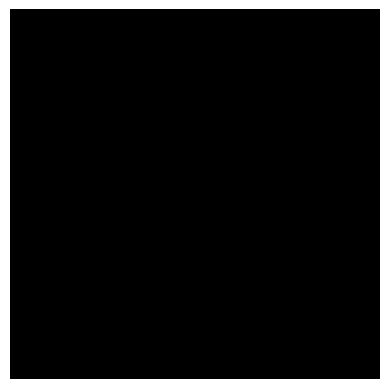

In [47]:
image_path = r"C:\Users\sneha\OneDrive\Documents\DNN\CNN\img2.png"

img = tf.keras.utils.load_img(
    image_path,
    target_size=(128, 128)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)[0][0]

if prediction >= 0.5:
    print(f"Prediction: Dog ({prediction:.2%})")
else:
    print(f"Prediction: Cat ({1 - prediction:.2%})")

plt.imshow(img)
plt.axis("off")
plt.show()

In [48]:
model.save("cat_dog_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [50]:
loaded_model = tf.keras.models.load_model("cat_dog_cnn.keras")

print("Saved model loaded successfully!")

prediction = loaded_model.predict(img_array, verbose=0)[0][0]

if prediction >= 0.5:
    print(f"Prediction: Dog ({prediction:.2%})")
else:
    print(f"Prediction: Cat ({1 - prediction:.2%})")
loaded_model.summary()

Saved model loaded successfully!
Prediction: Cat (76.66%)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_25 (Conv2D)                   │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_24 (MaxPooling2D)      │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_26 (Conv2D)                   │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_25 (MaxPooling2D)      │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_27 (Conv2D)                   │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_26 (MaxPooling2D)      │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_5 (Flatten)                  │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,914,309 (37.82 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,609,540 (25.21 MB)

In [51]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

print("Data augmentation layers created!")

Data augmentation layers created!


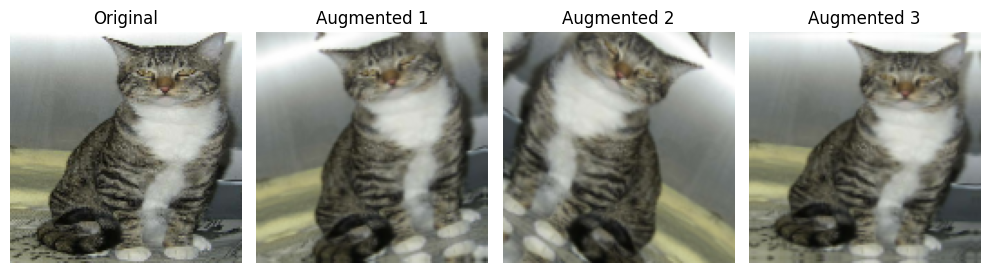

In [52]:

for images, labels in train_ds.take(1):
    sample_image = images[0]

    plt.figure(figsize=(10, 4))

    # Display the original image
    plt.subplot(1, 4, 1)
    plt.imshow(sample_image.numpy())
    plt.title("Original")
    plt.axis("off")

    # Display 3 augmented versions
    for i in range(3):
        augmented_image = data_augmentation(
            tf.expand_dims(sample_image, axis=0),
            training=True
        )[0]

        plt.subplot(1, 4, i + 2)
        plt.imshow(
            tf.clip_by_value(augmented_image, 0, 1).numpy()
        )
        plt.title(f"Augmented {i + 1}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [53]:

model_aug = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Data augmentation
    data_augmentation,

    # Convolution and pooling layers
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model_aug.summary()


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_11 (Sequential)           │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_34 (Conv2D)                   │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_33 (MaxPooling2D)      │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_35 (Conv2D)                   │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_34 (MaxPooling2D)      │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_36 (Conv2D)                   │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_35 (MaxPooling2D)      │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_8 (Flatten)                  │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [54]:

model_aug.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Augmented CNN compiled successfully!")


Augmented CNN compiled successfully!


In [55]:

history_aug = model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)


Epoch 1/5


C:\Users\sneha\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


500/500 ━━━━━━━━━━━━━━━━━━━━ 148s 264ms/step - accuracy: 0.6062 - auc: 0.6544 - loss: 0.6569 - precision: 0.6025 - recall: 0.6151 - val_accuracy: 0.6760 - val_auc: 0.7666 - val_loss: 0.5871 - val_precision: 0.6488 - val_recall: 0.7758
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 139s 261ms/step - accuracy: 0.6902 - auc: 0.7576 - loss: 0.5849 - precision: 0.6981 - recall: 0.6756 - val_accuracy: 0.7055 - val_auc: 0.8132 - val_loss: 0.5638 - val_precision: 0.6552 - val_recall: 0.8742
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 145s 272ms/step - accuracy: 0.7304 - auc: 0.8043 - loss: 0.5369 - precision: 0.7447 - recall: 0.7044 - val_accuracy: 0.7380 - val_auc: 0.8201 - val_loss: 0.5215 - val_precision: 0.7647 - val_recall: 0.6943
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 152s 286ms/step - accuracy: 0.7541 - auc: 0.8340 - loss: 0.5036 - precision: 0.7624 - recall: 0.7388 - val_accuracy: 0.7235 - val_auc: 0.8265 - val_loss: 0.5406 - val_precision: 0.6817 - val_recall: 0.8565
Epoch 5/5
500/500 ━━━━━━━━━━━━

In [56]:

# Evaluate the original CNN
original_results = model.evaluate(test_ds, return_dict=True, verbose=0)

# Evaluate the augmented CNN
augmented_results = model_aug.evaluate(test_ds, return_dict=True, verbose=0)

# Compare both models
import pandas as pd

comparison_aug = pd.DataFrame({
    "Original CNN": original_results,
    "CNN with Augmentation": augmented_results
})

print(comparison_aug.round(4))


           Original CNN  CNN with Augmentation
accuracy         0.8406                 0.7784
auc              0.9190                 0.8855
loss             0.3712                 0.4650
precision        0.8730                 0.7222
recall           0.7972                 0.9048


In [57]:

mild_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05)
])

print("Mild data augmentation created!")


Mild data augmentation created!


In [58]:

model_mild = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Mild data augmentation
    mild_augmentation,

    # Convolution and pooling layers
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model_mild.summary()


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_13 (Sequential)           │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_37 (Conv2D)                   │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_36 (MaxPooling2D)      │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_38 (Conv2D)                   │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_37 (MaxPooling2D)      │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_39 (Conv2D)                   │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_38 (MaxPooling2D)      │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_9 (Flatten)                  │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [59]:

model_mild.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Mild augmentation CNN compiled successfully!")


Mild augmentation CNN compiled successfully!


In [ ]:

history_mild = model_mild.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)


Epoch 1/5


C:\Users\sneha\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


235/500 ━━━━━━━━━━━━━━━━━━━━ 58s 222ms/step - accuracy: 0.5384 - auc: 0.5581 - loss: 0.6893 - precision: 0.5365 - recall: 0.5395